# Oscar — 01: EDA and data transforms (working)

Prepares the shared split for logistic regression and SVM. Needs
`report/01-Data.ipynb` to have been run. Only `train` and `validation` are loaded;
the test set is left alone until the end.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent            # this notebook runs from Oscar/
PROCESSED = ROOT / "data" / "processed"

train = pd.read_csv(PROCESSED / "taiwan-train.csv", index_col="ID")
validation = pd.read_csv(PROCESSED / "taiwan-validation.csv", index_col="ID")

Y = "default payment next month"    # the label: 1 = defaulted
X_train, y_train = train.drop(columns=Y), train[Y]
X_val, y_val = validation.drop(columns=Y), validation[Y]
print("X_train:", X_train.shape, "  X_val:", X_val.shape)

X_train: (17997, 23)   X_val: (5999, 23)


Fixes 1 and 3 both turn a coded column into yes/no (0/1) columns, one per code,
so one helper does both. The list of codes is fixed in advance, so train and
validation always get the same columns, even if a code is missing from one of them.

In [2]:
def one_hot(df, col, codes, reference):
    """Replace column `col` with one 0/1 column per code, dropping `reference`."""
    values = pd.Categorical(df[col], categories=codes)
    dummies = pd.get_dummies(values, prefix=col, dtype=int)
    dummies.index = df.index
    # The reference code is dropped: it is what a row of all zeros means.
    # Keeping it would make the columns add up to 1 on every row, which
    # duplicates the model's intercept.
    dummies = dummies.drop(columns=f"{col}_{reference}")
    return df.drop(columns=col).join(dummies)

## Fix 1: repayment status `PAY_1`…`PAY_6` as categories

As shown in Sprint 0 (Butler, Robinson & Mulryan, 2026) and Figure 1.1 of
`report/01-Data.ipynb`: codes -2, -1 and 0 default at the same low rate and the
jump comes at 1 month late, so the codes are not a count of months. Each code
gets its own column. Codes 3–8 are merged into "3+" because 4–8 are rare.
Reference level: -1, paid on time.

In [3]:
STATUS = [f"PAY_{i}" for i in range(1, 7)]
STATUS_CODES = [-2, -1, 0, 1, 2, 3]       # 3 now means "3 or more months late"

print("PAY_1 codes in train:", X_train["PAY_1"].value_counts().sort_index().to_dict())

def fix_status(df):
    df = df.copy()
    for col in STATUS:
        df[col] = df[col].clip(upper=3)   # merge 3-8 into 3
        df = one_hot(df, col, STATUS_CODES, reference=-1)
    return df

X_train1, X_val1 = fix_status(X_train), fix_status(X_val)
print("columns:", X_train.shape[1], "->", X_train1.shape[1])
X_train1.filter(like="PAY_1_").head()

PAY_1 codes in train: {-2: 1683, -1: 3424, 0: 8834, 1: 2183, 2: 1589, 3: 195, 4: 50, 5: 17, 6: 4, 7: 6, 8: 12}
columns: 23 -> 47


,PAY_1_-2,PAY_1_0,PAY_1_1,PAY_1_2,PAY_1_3
ID,,,,,
1,0,0,0,1,0
2,0,0,0,0,0
4,0,1,0,0,0
5,0,0,0,0,0
6,0,1,0,0,0


## Fix 2: signed log of the money amounts

Credit limit, bills and payments are money amounts. Two questions decide whether
to transform them:

1. Are they so lopsided that a few customers dominate? (Figure 2.1)
2. Is their link to default a straight line on the scale logistic regression
   uses? (Figure 2.2)

Shown for `LIMIT_BAL` and September's `BILL_AMT1` and `PAY_AMT1`; the other months
have similar skew (table at the end of this section). Some amounts are 0 and some
bills are negative (overpaid), so a plain log fails. We use the **signed log**,
sign(x) × log(1 + |x|), which keeps 0 at 0 and negatives negative.

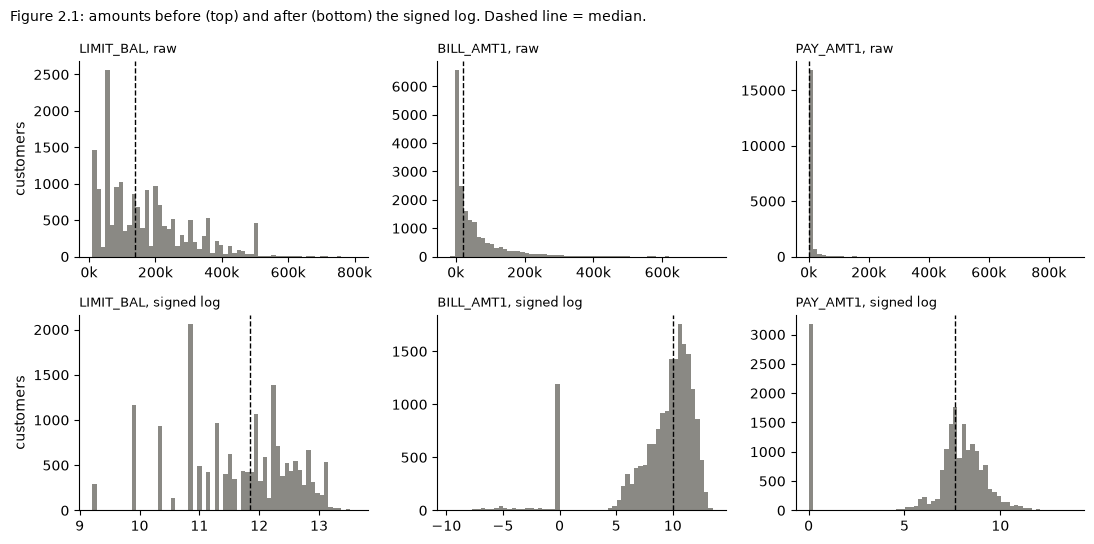

LIMIT_BAL  median   140,000   99th percentile   500,000   max   800,000
BILL_AMT1  median    22,398   99th percentile   349,164   max   746,814
PAY_AMT1   median     2,100   99th percentile    65,786   max   873,552


In [4]:
import matplotlib.pyplot as plt

AMOUNTS = (["LIMIT_BAL"] + [f"BILL_AMT{i}" for i in range(1, 7)]
           + [f"PAY_AMT{i}" for i in range(1, 7)])

def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))   # log1p(a) = log(1 + a)

SHOW = ["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]
GREY = "#8a8984"                               # same grey as Figure 1.1

fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for j, col in enumerate(SHOW):
    raw = X_train[col]
    for ax, values, scale in [(axes[0, j], raw, "raw"),
                              (axes[1, j], signed_log(raw), "signed log")]:
        ax.hist(values, bins=60, color=GREY)
        ax.axvline(values.median(), color="black", lw=1, ls="--")
        ax.set_title(f"{col}, {scale}", loc="left", fontsize=9)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0, j].xaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
for ax in axes[:, 0]:
    ax.set_ylabel("customers")
fig.suptitle("Figure 2.1: amounts before (top) and after (bottom) the signed log. "
             "Dashed line = median.", x=0.01, ha="left", fontsize=10)
fig.tight_layout()
plt.show()

for col in SHOW:
    x = X_train[col]
    print(f"{col:<10} median {x.median():>9,.0f}   "
          f"99th percentile {x.quantile(0.99):>9,.0f}   max {x.max():>9,.0f}")

**Figure 2.1.** On the raw scale most customers are squeezed into the first few
bars. Half of September payments are below 2,100, but the largest is 873,552, so a
straight-line model would let a handful of huge values pull the fit. After the
signed log the bulk is roughly bell-shaped. Customers with a bill or payment of
exactly 0 now stand apart as a spike.

Logistic regression assumes each input moves the **log-odds** of default,
log(p / (1 − p)), along a straight line. Figure 2.2 checks this: customers are
sorted by amount into 20 equal-sized groups, and each dot is one group's default
rate on the log-odds scale.

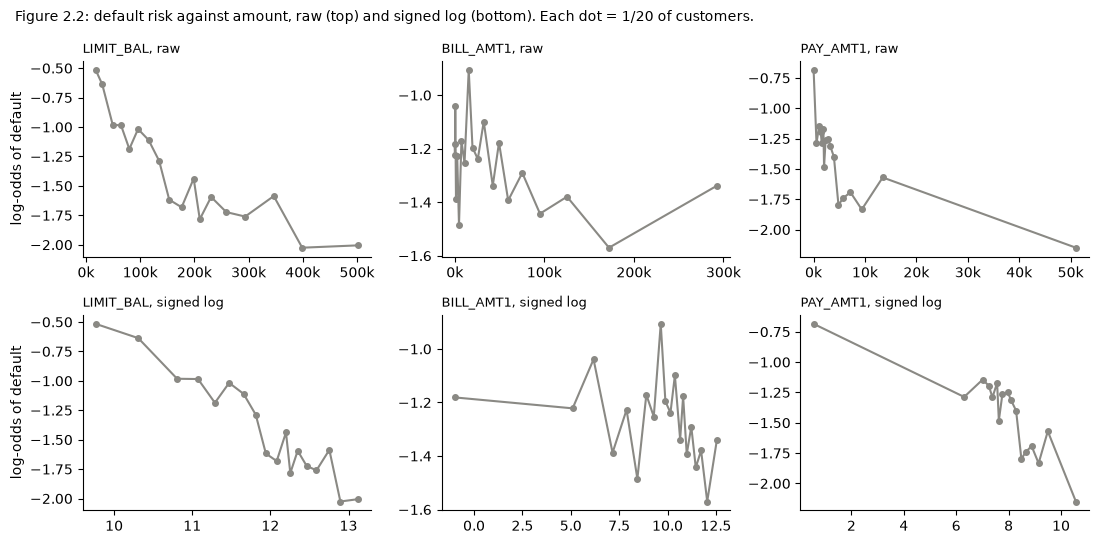

default rate: paid 0 in September 35%, paid something 19%, all 22%


In [5]:
def default_log_odds(x, y, n_bins=20):
    """Mean of x and log-odds of default in n_bins equal-sized groups along x."""
    bins = pd.qcut(x, n_bins, duplicates="drop")   # ties (e.g. many 0s) merge groups
    rate = y.groupby(bins, observed=True).mean()
    return x.groupby(bins, observed=True).mean(), np.log(rate / (1 - rate))

fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for j, col in enumerate(SHOW):
    raw = X_train[col]
    for ax, values, scale in [(axes[0, j], raw, "raw"),
                              (axes[1, j], signed_log(raw), "signed log")]:
        centre, log_odds = default_log_odds(values, y_train)
        ax.plot(centre, log_odds, "o-", color=GREY, ms=4, lw=1.5)
        ax.set_title(f"{col}, {scale}", loc="left", fontsize=9)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0, j].xaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
for ax in axes[:, 0]:
    ax.set_ylabel("log-odds of default")
fig.suptitle("Figure 2.2: default risk against amount, raw (top) and signed log "
             "(bottom). Each dot = 1/20 of customers.", x=0.01, ha="left", fontsize=10)
fig.tight_layout()
plt.show()

zero_paid = X_train["PAY_AMT1"] == 0
print(f"default rate: paid 0 in September {y_train[zero_paid].mean():.0%}, "
      f"paid something {y_train[~zero_paid].mean():.0%}, all {y_train.mean():.0%}")

**Figure 2.2.**

* `LIMIT_BAL`: on the raw scale risk falls steeply, then levels off, a curve. On
  the log scale it is close to a straight line, which the model can fit.
* `PAY_AMT1`: on the raw scale almost every group is crushed against the left edge.
  On the log scale customers who paid something fall along a rough line, but those
  who paid nothing sit well above it (the first dot): 35% of them default, against
  19% of those who paid something.
* `BILL_AMT1`: little link to default on either scale. For bills the log only
  tames the long tail; it doesn't straighten anything.

**Conclusion:** take the signed log of every amount.

In [6]:
def fix_amounts(df):
    df = df.copy()
    df[AMOUNTS] = signed_log(df[AMOUNTS])
    return df

X_train2, X_val2 = fix_amounts(X_train1), fix_amounts(X_val1)

# Skewness: 0 is symmetric, large positive = long right tail
pd.DataFrame({"before": X_train1[AMOUNTS].skew(),
              "after": X_train2[AMOUNTS].skew()}).round(1)

,before,after
LIMIT_BAL,1.0,-0.5
BILL_AMT1,2.6,-2.1
BILL_AMT2,2.6,-1.9
BILL_AMT3,3.3,-1.8
BILL_AMT4,2.8,-1.8
BILL_AMT5,2.8,-1.7
BILL_AMT6,2.7,-1.5
PAY_AMT1,16.8,-1.3
PAY_AMT2,32.6,-1.2
PAY_AMT3,16.5,-1.1


## Fix 3: `SEX`, `EDUCATION`, `MARRIAGE` as categories

These are labels, not quantities: default rate by `EDUCATION` is not a straight line
in the code (code 4, "others", is the lowest). Reference level for each: code 1.

In [7]:
DEMOGRAPHICS = {"SEX": [1, 2],              # 1 = male, 2 = female
                "EDUCATION": [1, 2, 3, 4],  # graduate, university, high school, others
                "MARRIAGE": [1, 2, 3]}      # married, single, others

print("default rate by EDUCATION:",
      train.groupby("EDUCATION")[Y].mean().round(3).to_dict())

def fix_demographics(df):
    for col, codes in DEMOGRAPHICS.items():
        df = one_hot(df, col, codes, reference=1)
    return df

X_train3, X_val3 = fix_demographics(X_train2), fix_demographics(X_val2)
assert list(X_train3.columns) == list(X_val3.columns)   # same columns in both
print("columns:", X_train2.shape[1], "->", X_train3.shape[1])

default rate by EDUCATION: {1: 0.194, 2: 0.236, 3: 0.255, 4: 0.061}


columns: 47 -> 50


## Fix 4: standardise every column

Rescale each column to mean 0 and standard deviation 1, so the penalty in logistic
regression and the distances in an SVM treat all columns alike. This is the only
step that learns from the data, so the means and standard deviations come from
**train only** and are then applied unchanged to validation.

In [8]:
scaler = StandardScaler().fit(X_train3)     # learns each column's mean and sd

def standardise(df):
    return pd.DataFrame(scaler.transform(df), index=df.index, columns=df.columns)

X_train4, X_val4 = standardise(X_train3), standardise(X_val3)

# Train is exactly mean 0, sd 1; validation is close but not exact, as expected
pd.DataFrame({"train mean": X_train4.mean(), "train sd": X_train4.std(),
              "val mean": X_val4.mean(), "val sd": X_val4.std()}).round(2).head(8)

,train mean,train sd,val mean,val sd
LIMIT_BAL,-0.0,1.0,-0.00,1.00
AGE,-0.0,1.0,0.00,1.00
BILL_AMT1,-0.0,1.0,0.00,1.00
BILL_AMT2,-0.0,1.0,0.01,0.99
BILL_AMT3,-0.0,1.0,0.01,0.99
BILL_AMT4,-0.0,1.0,0.01,0.99
BILL_AMT5,0.0,1.0,0.01,0.99
BILL_AMT6,-0.0,1.0,0.01,1.00


## Result

`X_train4` and `X_val4` are ready for modelling, with labels `y_train` and `y_val`.
The same fixes are in `prep.py` for the model notebooks; the check below
confirms it gives exactly the same result.

In [9]:
import prep

check_train, check_val = prep.transform(X_train, X_val)
assert check_train.equals(X_train4) and check_val.equals(X_val4)
print("prep.py matches fixes 1-4 above.")

print("X_train4:", X_train4.shape, "  X_val4:", X_val4.shape)
print(list(X_train4.columns))

prep.py matches fixes 1-4 above.
X_train4: (17997, 50)   X_val4: (5999, 50)
['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'PAY_1_-2', 'PAY_1_0', 'PAY_1_1', 'PAY_1_2', 'PAY_1_3', 'PAY_2_-2', 'PAY_2_0', 'PAY_2_1', 'PAY_2_2', 'PAY_2_3', 'PAY_3_-2', 'PAY_3_0', 'PAY_3_1', 'PAY_3_2', 'PAY_3_3', 'PAY_4_-2', 'PAY_4_0', 'PAY_4_1', 'PAY_4_2', 'PAY_4_3', 'PAY_5_-2', 'PAY_5_0', 'PAY_5_1', 'PAY_5_2', 'PAY_5_3', 'PAY_6_-2', 'PAY_6_0', 'PAY_6_1', 'PAY_6_2', 'PAY_6_3', 'SEX_2', 'EDUCATION_2', 'EDUCATION_3', 'EDUCATION_4', 'MARRIAGE_2', 'MARRIAGE_3']
